Billy York

08/17/26

# Automated Retraining

## Introduction

This milestone introduces automating the creation of Machine Learning models. It walks through creating a new batch job to train on the new data that has arrived since the last model was trained and deploying the model to be used and evaluated. 

## Design Decisions for Training Job

The interesting design decisions primarily happened after the model training job was complete. There was one during though which was how to shrink the Random Forest Regressor. The process was mainly trial and error of different hyperparameters and looking at the error metrics and the size of the final model. Afterwards, I ran into the prediction service and evaluation jobs not being designed for multiple model types. The prediction service does not get its input data from the database and therefore does not know the ids of the events like the evaluation service does. The evaluation service was not storing which model was used for evaluation like the prediction service does. The end result was simply returning the `model_id` from the prediction service in every possible response. I then had to add an endpoint to get the `model_id` because the evaluation service needs to know which model it is evaluating before it begins receiving results from the prediciton service as it needs to filter the events that have already been evaluated using that model. 

### Trained Model Table Schema

```sql
CREATE TABLE trained_models (
    id SERIAL PRIMARY KEY,
    model_id TEXT NOT NULL,
    r2 DOUBLE PRECISION NOT NULL,
    mape DOUBLE PRECISION NOT NULL,
    rmse DOUBLE PRECISION NOT NULL,
    time DOUBLE PRECISION NOT NULL,
    model BYTEA
)
```

## The Training Job Running

### Running containers

![Docker PS Output](./milestone6_1.png)

### PostgreSQL `\d`

![All Tables](./milestone6_2.png)

### PostgreSQL `\d trained_models`

![Trained Models](./milestone6_3.png)

### PostgreSQL `\d evaluated_home_sale_events`

![Evaluated Home Sale Events](./milestone6_4.png)

### PostgreSQL `\d evaluated_event_ids`

![Evaluated Event Ids](./milestone6_5.png)

## Analysis of New Model from Training Job

### True Price vs Predicted Price

![True Price vs Predicted Price](./milestone6_6.png)

This is fairly similar to the old model, as the true price goes up, so does the error in prediction. There is still a fairly strong correlation, so the model isn't extremely far off in any case. 

### RMSE of Old and New Models by Sale Event Date

![RMSE](./milestone6_7.png)

There are a few interesting things happening here. First, the new model almost completely mirrors the old model, just offset from it by some amount. Then that there is a noticeable increase in error in the early period, before the Economic Conditions started changing before the old model jumps up significantly and the new one stays about in line with the early period. The last interesting thing that I don't know what to make of is that they are trending in opposite directions, even crossing again as of todays sale events. My best guess is the data from the simulator is only half completed for the day and as it goes on this would even out. 

### R2 Score of Old and New Models by Sale Event Date

![R2 Score](./milestone6_8.png)

We see a similar pattern here, just in reverse. The main difference in behavior from the RMSE plot is that while the new model does sharply dip on the newest data, the old model simply decreases its descent. 

### MAPE of Old and New Models by Sale Event Date

![MAPE](./milestone6_9.png)

This chart shows very similar behavior to the previous two. It shows that the new model is off by about +/- 4% of the true price and the old model went from about +/- 3.7% to +/- 4.3%. If the trend with the new model continues, then it will be worse than the old model again. 

## MLOps Maturity Evaluation

### People

This system could be considered a Level 3 or a Level 0/1 as being a solo developer means there is only one person in all roles, so there is complete collaboration on every step, but then they are also technically working in isolation. Realistically if done on team of 2 or 3, it would still likely score at a Level 3 since there are no middle men for handing off code or data. It's not a Level 4 because the expanded responsibilities listed in the Maturity Model are not required for this system.

Improving to a level 4 means adding more responsibility to the people on the team, so adding metric tracking and data markers for example. This could be in the form of some full dashboard system to display these metrics so everyone can view and discuss them as a team. 

### Model Creation

This system is somewhere between a Level 1 and a Level 2. There is a Data pipeline automatically gathering data, experiment results from the evaluation job are tracked, and the training job is version controlled. The models themselves are not necessarily version controlled, besides the first one, but they are versioned and stored in the database. Lastly, the compute is not managed in a meaningful way. 

The compute being managed is the main thing holding this area back from fully being at Level 2, so the solution is likely to switch off the virtual machine and move the containers to something like Elastic Beanstalk so they can spin up and down as needed instead of having the virtual machine constantly on. 

### Model Release

This system is around a Level 1. There is no requirement to use something like GitHub Actions to build/deploy on push/merge. I imagine this is due to both time constraints and constraints on getting the Actions through the school's firewall. The Scoring script is automated, but does not have tests, the results are simply stored alongside the model in the database. 

Right now the only way a new model version will get used is by kicking over the second prediction services container and restarting it. Something simple like adding a function for an APScheduler job to trigger every day when a new model is trained for the prediction service to retrieve the new one would bring this area to Level 2.

### Application Integration

This system is a Level 0 aspiring towards Level 1. Only one module was required to have tests, application releases are manual even if the model release is automated. There are basic integration tests in the form of "Can we consistently get a correct looking response without the application blowing up?"

The easiest way to improve this area is to add significantly more tests for each module. Otherwise adding automated GitHub Actions for building and deploying each module would be very doable, with the huge caveat of getting them to the virtual machine behind the firewall. I know GitLab has a system where you can connect a Kubernetes cluster to a pipeline in like a websocket configuration so it can pull new images and relaunch the containers as the pipeline builds them.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import psycopg
import seaborn as sns
from psycopg.rows import dict_row
from sklearn.metrics import (
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)

In [2]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [3]:
conn_string = 'postgresql://{}:{}@{}:5432/house_price_prediction_service'.format(user, password, host)
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT id, sale_date, true_price, predicted_price, model_id FROM evaluated_home_sale_events;')
        rows = cur.fetchall()

In [4]:
df = pd.DataFrame.from_records(rows)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 465826 entries, 0 to 465825
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   id               465826 non-null  int64         
 1   sale_date        465826 non-null  datetime64[us]
 2   true_price       465826 non-null  float64       
 3   predicted_price  465826 non-null  float64       
 4   model_id         465826 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 17.8 MB


In [5]:
model_groups = df.groupby(by='model_id')
records = []
prices = []
for model_group in model_groups:
    grouped = model_group[1].groupby(by=model_group[1]['sale_date'].dt.date)
    for group in grouped:
        rmse = root_mean_squared_error(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
        r2 = r2_score(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
        mape = mean_absolute_percentage_error(y_true=group[1]['true_price'], y_pred=group[1]['predicted_price'])
        record = {'model': model_group[0], 'date': group[0], 'date_label': f'{group[0].month}-{group[0].day}', 'rmse': rmse, 'r2': r2, 'mape': mape}
        records.append(record)
stats = pd.DataFrame.from_records(records)
stats = stats.sort_values(by='date')
stats.head()

,model,date,date_label,rmse,r2,mape
0,2026.8.17,2026-06-01,6-1,34085.967006,0.991106,0.039703
79,first-version,2026-06-01,6-1,33219.586478,0.991553,0.037238
80,first-version,2026-06-02,6-2,28515.057352,0.992097,0.036889
1,2026.8.17,2026-06-02,6-2,30254.867801,0.991104,0.039963
2,2026.8.17,2026-06-03,6-3,30689.350958,0.991944,0.039518


[Text(0.5, 1.0, 'True vs Predicted Price'),
 Text(0.5, 0, 'True Price'),
 Text(0, 0.5, 'Predicted Price')]

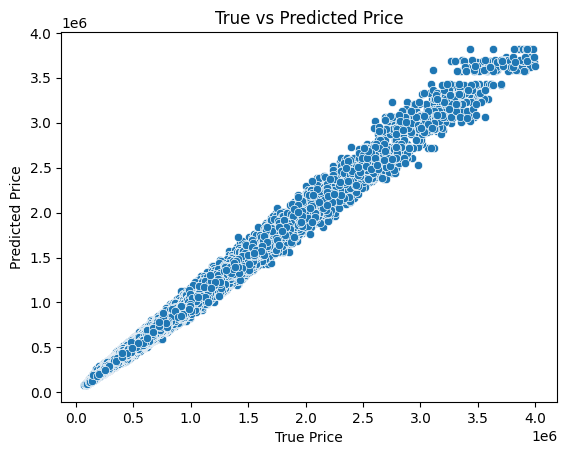

In [6]:
sns.scatterplot(x=df.iloc[df['model_id']=='2026.8.17']['true_price'], y=df.iloc[df['model_id']=='2026.8.17']['predicted_price']).set(title='True vs Predicted Price', xlabel='True Price', ylabel='Predicted Price')

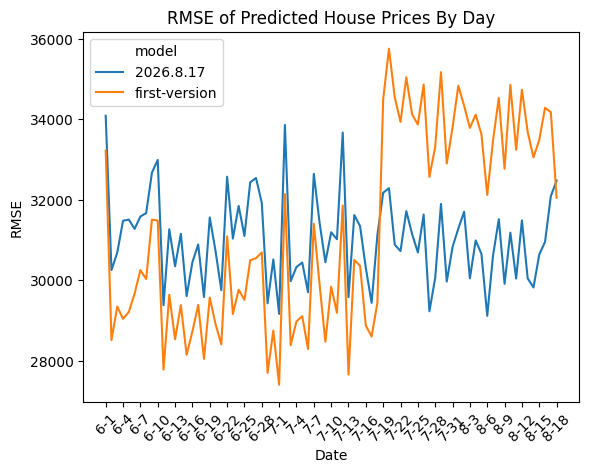

In [7]:
rmse_lp = sns.lineplot(x=stats['date'], y=stats['rmse'], hue=stats['model'])
rmse_lp.set(title='RMSE of Predicted House Prices By Day', xlabel='Date', ylabel='RMSE')
rmse_lp.set_xticks(ticks=stats.iloc[stats['model']=='first-version']['date'][::3], labels=stats.iloc[stats['model']=='first-version']['date_label'][::3], rotation=45)
plt.show()

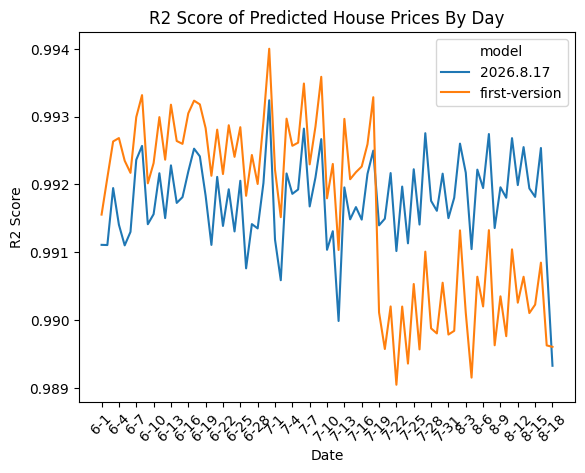

In [8]:
r2_lp = sns.lineplot(x=stats['date'], y=stats['r2'], hue=stats['model'])
r2_lp.set(title='R2 Score of Predicted House Prices By Day', xlabel='Date', ylabel='R2 Score')
r2_lp.set_xticks(ticks=stats.iloc[stats['model']=='first-version']['date'][::3], labels=stats.iloc[stats['model']=='first-version']['date_label'][::3], rotation=45)
plt.show()

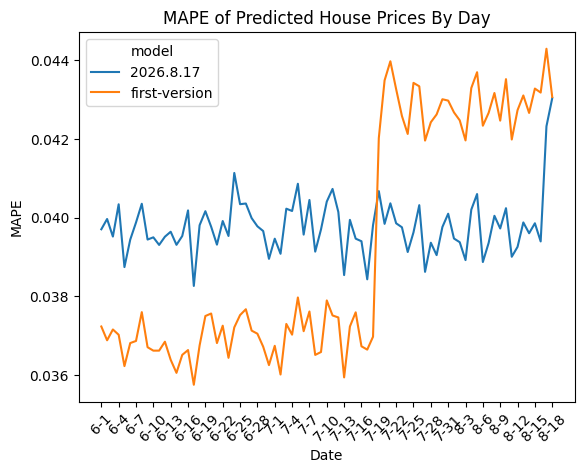

In [9]:
mape_lp = sns.lineplot(x=stats['date'], y=stats['mape'], hue=stats['model'])
mape_lp.set(title='MAPE of Predicted House Prices By Day', xlabel='Date', ylabel='MAPE')
mape_lp.set_xticks(ticks=stats.iloc[stats['model']=='first-version']['date'][::3], labels=stats.iloc[stats['model']=='first-version']['date_label'][::3], rotation=45)
plt.show()